# Problem 1

First, you need to be familiar with the dataset. Answer the following questions in well-written
paragraphs

1. [4 points] Why did you choose this dataset, and why is it interesting to you? (Make sure you include
a link to the dataset that you chose).

https://snap.stanford.edu/data/ego-Facebook.html
We chose this graph because it is a reasonable size with 4,039 nodes and 88,234 edges, which is large enough to show real network patterns but small enough to analyze efficiently. It's also a simple graph  no edge weights or directions and 00% of nodes are already in the largest connected component. This will make preprossing the data much easier.

2. [3 points] Did you preprocess the data? If so, how did you preprocess it? Clearly explain the process.
e.g., Did you take the largest connected component? Was it manageable, if not, did you sample it?
How did you take the sample of the graph? What did you do after sampling? Did you do any other
preprocessing? etc.

We loaded the dataset as an edge list and turned it into a graph. We then extracted the largest connected component since the assignment required it, but the dataset was already fully connected, so nothing was removed. The dataset was small enough that we didn’t need to sample the graph. After that, we converted the edges into a list of tuples so we could use them in our functions. Finally, we removed any possible duplicates

3. [2 points] Explain what type of data is represented in this dataset

This dataset is a Facebook social network graph. Each node represents a user, and each edge represents a friendship between two users. The data is anonymized, so there are no real names or personal details, only the connections between users in the ego-Facebook Social Network Dataset.

4. [6 points] Answer the following questions before doing the analysis.

a. [2 points] What characteristic do you expect the nodes with high centrality to possess? E.g.,
what type of non-graph characteristic would you expect the nodes with high centrality have?
Note that this answer depends on the dataset that you choose.

Nodes with high centrality are likely to be users who are very socially active in the network. These users probably have many mutual friendships and may connect different friend groups together by being involved in multiple social circles and having friends across different groups or communities. For example, someone who is well connected socially in real life such as a person who interacts with many groups of people would be a high-centrality node.

b. [2 points] Do you think this graph dataset would exhibit power law? State your reasons.

From my own anecdotal experience, most people are part of a close knit friend group, and the people I know who are very social tend to be exceptions and they are also friends with many different groups. This aligns with power law behavior, where a few nodes have very high degree while most nodes have very low degree.

c. [2 points] Do you expect this graph to have small-world property? State your reasons.

I’d think so. I’d expect the graph to have high clustering where people form tight friend groups and where friends of friends are often friends with each other. I also suspect that nodes with high centrality help connect different friend groups together. Because of this, most people belong to tightly connected friend groups but can still reach other groups through only a few connections.

# Problem 2

Implement the following functions in Python. You can assume that the graph is simple, i.e., the graph
does not have self-loops and parallel edges, undirected, unweighted. You can use networkx libraries as
long as the function does not perform the same task as what you are being asked to implement. For
example, if you are asked to implement a function that calculates betweenness centrality, then you can
use networkx function to find shortest paths, but you cannot use the networkx function that calculates
the betweenness centrality in your implementation. Also, you can assume that nodes labels are integers.
Test each of your functions on facebook_combined dataset.

In [ ]:
import networkx as nx
import numpy as np
from networkx.classes import nodes

# Load graph as edge list
G = nx.read_edgelist("facebook_combined.txt", nodetype=int)

#Extract largest connected component
largest_cc = max(nx.connected_components(G), key=len)
G_lcc = G.subgraph(largest_cc).copy()

#Convert edges to list of tuples
edges = list(G_lcc.edges())

# Remove duplicates (if any) and sort each edge
edges = list({tuple(sorted(edge)) for edge in edges})

print("Number of nodes:", G_lcc.number_of_nodes())
print("Number of edges:", G_lcc.number_of_edges())
print("Number of edges in tuple list:", len(edges))


1. [5 points] Implement a function that takes list of edges of a graph—represented as tuples—and
output the number of nodes.

In [ ]:
def node_count(nodeList):

    nodes = []
    for edge in nodeList:
        node1 = edge[0]
        node2 = edge[1]

        if node1 not in nodes:
            nodes.append(node1)
        if node2 not in nodes:
            nodes.append(node2)

    return len(nodes)


print(node_count(edges))

2. [5 points] Implement a function that takes list of edges of a graph—represented as tuples—and an
input vertex index as input and output the degree of the input vertex.

In [ ]:
# note this won't work if the node list has duplicate edges, but we confirmed that the data set does not in the preprocessing phase.

def node_degree(node_list, node):
    count = 0
    for edge in node_list:
        if node in edge:
            count += 1

    return count


3. [5 points] Implement a function that takes list of edges of a graph—represented as tuples—and
output the adjacency matrix of the graph.

In [ ]:
def adjacency_matrix(edge_list):
    nodes = set()
    for u, v in edge_list:
        nodes.add(u)
        nodes.add(v)
    n = max(nodes) + 1

    # create n x n matrix initialized with 0
    matrix = []
    for i in range(n):
        row = [0] * n  # a row of n zeros
        matrix.append(row)

    # fill in edges
    for u, v in edge_list:
        matrix[u][v] = 1
        matrix[v][u] = 1
    return matrix




print(adjacency_matrix(edges))

4. [5 points] Implement a function that takes list of edges of a graph—represented as tuples—and
output the degree distribution of the graph. Output the degree distribution as a python list.

In [ ]:
def degree_distribution(edge_list):

    # get all nodes
    nodes = set()
    for edge in edge_list:
        nodes.add(edge[0])
        nodes.add(edge[1])

    # find maximum degree to size the list
    max_deg = 0
    for node in nodes:
        deg = node_degree(edge_list, node)
        if deg > max_deg:
            max_deg = deg

    # initialize distribution list
    distribution = [0] * (max_deg + 1)

    # count how many nodes have each degree
    for node in nodes:
        deg = node_degree(edge_list, node)
        distribution[deg] += 1

    return distribution

In [ ]:
print(degree_distribution(edges)) #this will take a minute or so to run

In [ ]:
""""
#for comparison only

degrees_nx = [d for n, d in G_lcc.degree()]  # list of degrees for all nodes
max_deg = max(degrees_nx)
dist_nx = [0] * (max_deg + 1)

for d in degrees_nx:
    dist_nx[d] += 1

print("NetworkX:", dist_nx)
"""

5. [5 points] Implement a function that takes degree distribution of a graph—represented as a list—
and input degree, then output the probability of picking a vertex with degree higher than or equal
to the input degree.

In [ ]:
def prob_degree_or_higher(degree_dist, k):

    total_nodes = sum(degree_dist)  # total number of nodes

    # avoid division by zero
    if total_nodes == 0:
        return 0

    # count nodes with degree >= k
    count_higher = 0
    for degree_index in range(k, len(degree_dist)):
        count_higher += degree_dist[degree_index]

    probability = count_higher / total_nodes
    return probability

In [ ]:
print(prob_degree_or_higher(degree_distribution(edges),24)) # take a minute or so to run

6. [5 points] Implement a function that takes input vertex index, and a list of edges of a graph—
represented as tuples—and output the eccentricity of the given vertex.

In [ ]:
def eccentricity(edge_list, node):
    # Build adjacency list
    adj = {}
    for u, v in edge_list:
        if u not in adj:
            adj[u] = []
        if v not in adj:
            adj[v] = []
        adj[u].append(v)
        adj[v].append(u)

    # BFS to find shortest path
    visited = {node: 0}
    queue = [node]

    while queue:
        current = queue.pop(0)
        for neighbor in adj.get(current, []):
            if neighbor not in visited:
                visited[neighbor] = visited[current] + 1
                queue.append(neighbor)

    ecc = max(visited.values())
    return ecc

7. [5 points] Implement a function that takes list of edges of a graph—represented as tuples—and
output the diameter of the graph. (you can use networkx function to find the shortest path between
two vertices)

In [ ]:
def graph_diameter(edge_list):

    # Build NetworkX graph
    G = nx.Graph()
    G.add_edges_from(edge_list)

    # Step 2: calculate eccentricity for each node
    diam = 0
    for node in G.nodes():
        # use NetworkX shortest path length from node to all others
        lengths = nx.single_source_shortest_path_length(G, node)
        ecc = max(lengths.values())
        if ecc > diam:
            diam = ecc

    return diam

8. [5 points] Implement a function that takes list of edges of a graph—represented as tuples—and
output the radius of the graph. (you can use networkx function to find the shortest path between
two vertices)

In [ ]:
def graph_radius(edge_list):
    G = nx.Graph()
    G.add_edges_from(edge_list)

    # Find the eccentricity for each node
    min_ecc = float('inf')
    for node in G.nodes():
        lengths = nx.single_source_shortest_path_length(G, node)
        ecc = max(lengths.values())
        if ecc < min_ecc:
            min_ecc = ecc

    return min_ecc

9. [5 points] Implement a function that takes vertex index and a list of edges of a graph—represented
as tuples—and output the clustering coefficient of the input vertex.

In [ ]:
def clustering_coef(edge_list, node):
    # Find the neighbors of the current node
    neighbors = set()
    for i, j in edge_list:
        if i == node:
            neighbors.add(j)
        elif j == node:
            neighbors.add(i)

    k = len(neighbors)
    if k < 2:
        return 0.0

    # Count edges among neighbors
    neighbor_edges = 0
    for i, j in edge_list:
        if i in neighbors and j in neighbors:
            neighbor_edges += 1

    return neighbor_edges / (k * (k - 1) / 2)

print(clustering_coef(edges, 0)) # test on node 0

10. [5 points] Implement a function that takes a vertex index and a list of edges of a graph—represented
as tuples—and output the betweenness centrality of the input vertex.

In [ ]:
def betweenness_centrality(edge_list, node):
    G = nx.Graph()
    G.add_edges_from(edge_list)
    nodes = list(G.nodes())
    n = len(nodes)

    sigma_through = 0
    sigma_total = 0

    for i in range(n):
        for j in range(i + 1, n):
            s = nodes[i]
            t = nodes[j]
            if s == node or t == node:
                continue

            # Find shortest pasths between s and t
            all_paths = list(nx.all_simple_paths(G, s, t))
            sigma_total += len(all_paths)

            # Find how many paths are through node
            count = 0
            for p in all_paths:
                if node in p:
                    count += 1

            sigma_through += count

    if sigma_total == 0:
        return 0.0

    # Normalize for undirected graph
    norm = (n - 1) * (n - 2) / 2
    return (sigma_through/ sigma_total) / norm

# print(betweenness_centrality(edges, 0)) # Takes A WHILE: Slow on large graphs, O(n^2) over all pairs

In [ ]:
# Test on a small graph: triangle with an extra node
# 0-1-2-0 (triangle), plus 1-3
# Node 1 sits on all paths from 3 to 0 and 3 to 2, so it should have the highest betweenness
test_edges = [(0,1),(1,2),(0,2),(1,3)]
print(betweenness_centrality(test_edges, 1))  # should be highest
print(betweenness_centrality(test_edges, 0))  # should be lower

11. [5 points] Implement a function that takes a vertex index and a list of edges of a graph—represented
as tuples—and output the closedness centrality of the input vertex.


In [ ]:
def closeness_centrality(edge_list, node):
    G = nx.Graph()
    G.add_edges_from(edge_list)

    lengths = nx.single_source_shortest_path_length(G, node)
    n = len(lengths)

    if n <= 1:
        return 0.0

    total_distance = sum(lengths.values())

    if total_distance == 0:
        return 0.0

    closeness = (n - 1) / total_distance
    return closeness

print(closeness_centrality(edges, 0))

12. [5 points] Implement power iteration to find the eigenvector centrality of each node in a network.
But there is a slight difference in the implementation. Instead of using 𝐿∞ norm for normalizing the
resultant vector at each iteration use 𝐿2(Euclidean distance) for normalization. You may use numpy
matrix multiplication library functions, transpose function, dot product functions, norm functions
but you may not use the libraries to directly calculate eigenvectors. You may assume that the inputs
to this function are the adjacency matrix and max number of iterations.

In [ ]:
def eigenvector_centrality(adj_matrix, max_iter=100):
    n = len(adj_matrix)
    A = np.array(adj_matrix, dtype=float)

    x = np.ones(n) / n

    for i in range(max_iter):
        x_new = np.zeros(n)
        for j in range(n):
            total = 0.0
            for k in range(n):
                total += A[j][k] * x[k]
            x_new[j] = total

        norm = np.linalg.norm(x_new, ord=2)
        if norm == 0:
            break
        x_new = x_new / norm

        if np.linalg.norm(x_new - x, ord=2) < 1e-10:
            break

        x = x_new

    return x

# print(eigenvector_centrality(adjacency_matrix(edges))) # will take many mins (8-9 mins)

In [ ]:
# Small test graph (not as long)
test_edges = [(0,1),(1,2),(0,2),(1,3)]
A = adjacency_matrix(test_edges)
print(eigenvector_centrality(A))

# Problem 3

Report the following, using tables or figures as appropriate. You may treat the graph as an undirected,
unweighted graph with no loops or parallel edges. You may use any networkx functions for all of Part 3,
but you are encouraged to use your functions from Part 2 on real-world data.

1. [5 points] Provide a visualization of the graph dataset that you chose. (If the dataset is too large, you
may visualize a sample of the graph.


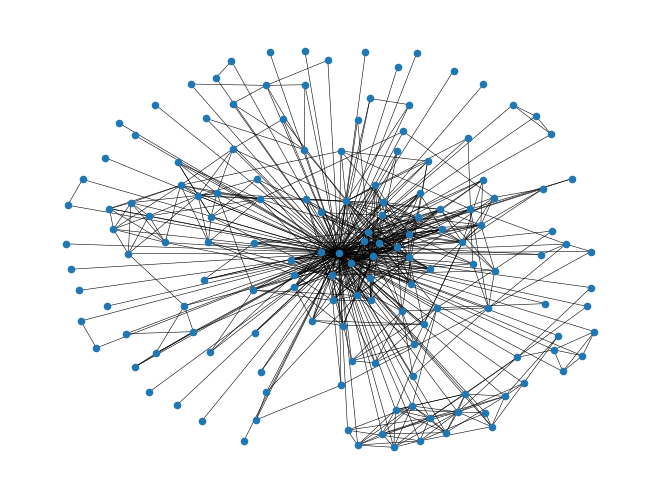

In [1]:
import networkx as nx

G = nx.read_edgelist("facebook_combined.txt")

largest_cc = max(nx.connected_components(G), key=len)
G_lcc = G.subgraph(largest_cc).copy()

sample_nodes = list(G_lcc.nodes())[:150]
G_sample = G_lcc.subgraph(sample_nodes)

nx.draw(G_sample, node_size=20, width=0.4, with_labels=False)

Because the network may contain disconnected pieces, we extracted the largest connected component. Since the full graph is very large, we visualized a sample of 150 nodes from this component to show the general structure of the network.

2. [3 points] List the 10 nodes with highest closedness centrality.


In [2]:
closeness = nx.closeness_centrality(G_sample)

closeness_top_10 = sorted(closeness.items(), key = lambda x: x[1], reverse = True)[:10]

for node, value in closeness_top_10:
    print(node, value)

0 1.0
56 0.5622641509433962
67 0.5622641509433962
25 0.5580524344569289
26 0.5518518518518518
119 0.5518518518518518
21 0.5477941176470589
122 0.5437956204379562
9 0.5437956204379562
98 0.5379061371841155


3. [3 points] List the 10 nodes with highest betweenness centrality.


In [3]:
betweenness = nx.betweenness_centrality(G_sample)

top_10_betweenness = sorted(betweenness.items(), key = lambda x: x[1], reverse = True)[:10]

for node, value in top_10_betweenness:
    print(node, value)


0 0.8725158087574192
25 0.011128284869895607
56 0.00946217506620191
119 0.00923650814590412
67 0.007075500280198266
21 0.005374323159558061
9 0.00388875212700716
26 0.0036368746939216727
122 0.002893534604944001
82 0.0018991546676110436


4. [3 points] List the 10 nodes with highest clustering coefficients.


In [4]:
clustering = nx.clustering(G_lcc)

top_10_clustering = sorted(clustering.items(), key=lambda x: x[1], reverse=True)[:10]

for node, value in top_10_clustering:
    print(node, value)

32 1.0
33 1.0
35 1.0
42 1.0
44 1.0
46 1.0
47 1.0
52 1.0
63 1.0
70 1.0


5. [3 points] Find the top 10 nodes ranked by the highest prestige/eigenvector centrality.


In [5]:
eigen = nx.eigenvector_centrality(G_lcc)

top_10_eigen = sorted(eigen.items(), key = lambda x: x[1], reverse = True)[:10]

for node, value in top_10_eigen:
    print(node, value)

1912 0.09540696149067629
2266 0.08698327767886552
2206 0.08605239270584342
2233 0.08517340912756598
2464 0.08427877475676092
2142 0.08419311897991795
2218 0.0841557356805503
2078 0.08413617041724977
2123 0.08367141238206224
1993 0.0835324284081597


6. [3 points] List the top 10 nodes ranked by PageRank.


In [8]:
import networkx as nx

pagerank = {node: 1/len(G_lcc) for node in G_lcc}
d = 0.85
N = len(G_lcc)

for _ in range(20):
    new_pagerank = {}
    for node in G_lcc:
        rank_sum = 0
        for neighbor in G_lcc.neighbors(node):
            rank_sum += pagerank[neighbor] / G_lcc.degree(neighbor)
        new_pagerank[node] = (1-d)/N + d*rank_sum
    pagerank = new_pagerank

top_10_pagerank = sorted(pagerank.items(), key=lambda x: x[1], reverse=True)[:10]

for node, value in top_10_pagerank:
    print(node, value)

3437 0.007577162948083981
107 0.006888754233055848
1684 0.006310961630949003
0 0.006229598028874037
1912 0.0038194663080224297
348 0.0023198004420035873
686 0.002216736076790357
3980 0.0021579632407423125
414 0.0017844266149043817
483 0.0012951727860082828


7. [4 points] Go through your answers on Problem 3 [2-6] sub questions. Are these highly ranked nodes
based on different centrality measurements the same or different? If there is a difference, is it
significant or not? Why do you think this is the case?


The nodes that rank highly across the different centrality measures are somewhat similar but not exactly the same. Some nodes, such as 107 and 1684, appear near the top in multiple measures, which suggests they are important in several ways within the network. However, other nodes rank highly in one measure but not in others.

The differences are not extremely large, but they are noticeable because each centrality measure captures a different type of importance. For example, closeness centrality measures how quickly a node can reach all other nodes, betweenness centrality measures how often a node lies on shortest paths between other nodes, clustering coefficient reflects how tightly connected a node’s neighbors are, and PageRank/eigenvector centrality measure influence based on connections to other important nodes.

Because social networks like Facebook contain clusters of friends and hub nodes that connect different groups, it is expected that different centrality measures will highlight slightly different nodes as important.

8. [3 points] Plot the log-log plot of the degree distribution of the graph—make sure that x-axis is the
log 𝑘 and y-axis is the log 𝑓(𝑘), where 𝑓(𝑘) is the probability that a random node we pick has
degree 𝑘. Make sure you draw the least-square fit line of the given data points as well. By looking at
the plot, do you think the graph exhibits power-law behavior?

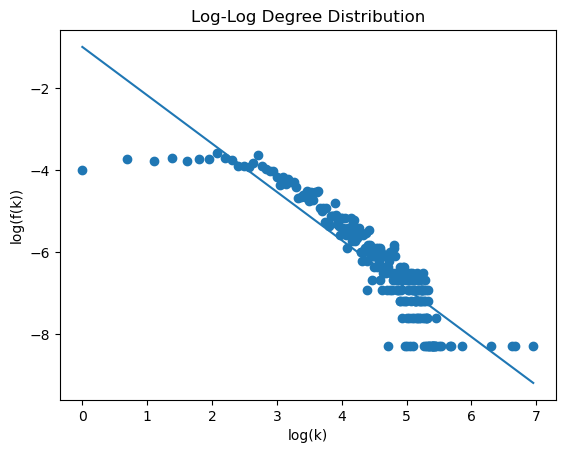

In [10]:
import numpy as np
import matplotlib.pyplot as plt

#get degree of every node
degrees = [d for n, d in G_lcc.degree()]

#count frequency of each degree
unique_deg, counts = np.unique(degrees, return_counts=True)

#probability distribution
prob = counts / counts.sum()

#log values
log_k = np.log(unique_deg)
log_fk = np.log(prob)

#least squares fit
slope, intercept = np.polyfit(log_k, log_fk, 1)
fit_line = slope * log_k + intercept

#plot
plt.scatter(log_k, log_fk)
plt.plot(log_k, fit_line)

plt.xlabel("log(k)")
plt.ylabel("log(f(k))")
plt.title("Log-Log Degree Distribution")
plt.show()

The log-log plot of the degree distribution shows the relationship between log(k) and log(f(k)), where k is the degree and f(k) is the probability of a node having that degree. The data points roughly follow a linear downward trend in log-log space, and the least squares fit line approximates this trend. This suggests that the Facebook network exhibits power-law behavior, which is common in social networks where many nodes have small degree and a small number of nodes act as highly connected hubs.